# 🏠 دليل المشتري: فين تشتري شقتك في مصر؟

## المقدمة

أي حد بيفكر يشتري شقة في مصر دلوقتي بيتوه.
كل إعلان بيقول "فرصة مش هتتكرر" وكل سمسار بيقول "السعر هيغلى بكرة".

المشروع ده اتعمل عشان يرد على سؤال واحد بس، بسؤال تاني أوضح:
**لو معاك فلوسك، تشتري فين؟ ومتشتريش فين؟**

احنا جمعنا بيانات **1000 شقة وفيلا حقيقية** من أكبر المواقع العقارية في مصر في 2026،
وعملنا ليها تنضيف وتحليل عشان نطلع بنتيجة واضحة مش كلام سماسرة.

### المشروع ده هيجاوب على 3 أسئلة بتقنع أي حد يشتري:

1. فين أرخص وأغلى كمبوند في سعر المتر؟
2. الفيلا ولا الشقة اللي سعر مترها أرخص؟
3. هل المساحة الكبيرة سعر مترها أرخص؟

> **الهدف مش إننا نتوقع سعر وخلاص، الهدف إننا نقول للمشتري: خد فلوسك وحطها هنا، ومتحطهاش هنا.**

In [1]:
import pandas as pd

# الداتا الأساسية - 1000 شقة
df_listings = pd.read_csv("hf://datasets/elsiddik/egypt-real-estate-prices-compounds-2026/data/egypt_real_estate_listings_1000.csv")

# الداتا المرجعية - متوسط سعر المتر لكل كمبوند
df_benchmarks = pd.read_csv("hf://datasets/elsiddik/egypt-real-estate-prices-compounds-2026/data/compound_benchmarks_egp_per_sqm.csv")

print("Listings:", df_listings.shape)
print("Benchmarks:", df_benchmarks.shape)

print("\n--- Listings Columns ---")
print(df_listings.columns.tolist())
print(df_listings.head(3))

print("\n--- Benchmarks Columns ---")
print(df_benchmarks.columns.tolist())
print(df_benchmarks.head(3))

Listings: (1000, 37)
Benchmarks: (97, 10)

--- Listings Columns ---
['title', 'portal', 'portalListingId', 'listingType', 'propertyType', 'city', 'district', 'compoundName', 'developerName', 'address', 'priceEgp', 'priceUsd', 'pricePerSqmEgp', 'currency', 'paymentMethod', 'downPaymentEgp', 'downPaymentPercent', 'installmentYears', 'monthlyInstallmentEgp', 'areaSqm', 'bedrooms', 'bathrooms', 'finishingStatus', 'furnished', 'completionStatus', 'deliveryDate', 'sellerType', 'agencyName', 'hasPhoneContact', 'latitude', 'longitude', 'listedAt', 'isVerified', 'dealScore', 'dealTier', 'url', 'scrapedAt']
               title portal portalListingId listingType propertyType  \
0     Duplex, Sawary   Nawy          101536        sale       Duplex   
1  Apartment, Sawary   Nawy          114731        sale    Apartment   
2  Apartment, Sawary   Nawy          117404        sale    Apartment   

         city    district compoundName                    developerName  \
0  Alexandria  Alexandria      

In [2]:
print(df_listings.isnull().sum())

title                      0
portal                     0
portalListingId            0
listingType                0
propertyType               1
city                       0
district                   4
compoundName             274
developerName            298
address                    0
priceEgp                   4
priceUsd                   4
pricePerSqmEgp            90
currency                   0
paymentMethod             81
downPaymentEgp           574
downPaymentPercent       572
installmentYears         657
monthlyInstallmentEgp    657
areaSqm                   90
bedrooms                  68
bathrooms                134
finishingStatus          461
furnished                607
completionStatus         165
deliveryDate             616
sellerType                 0
agencyName                 7
hasPhoneContact            0
latitude                 393
longitude                393
listedAt                 393
isVerified               393
dealScore                  0
dealTier      

## 🧹 تنضيف الداتا: مسح الأعمدة الفاضية واللي ملهاش لازمة

مسحنا 15 عمود: أعمدة التقسيط الفاضية، أعمدة الموقع، وأعمدة زي اللينك وتاريخ الرفع اللي مش هتفيد في التحليل.
كنا 37 عمود، بعد المسح بقينا 22 عمود نضاف بس.

In [3]:
# هنعمل نسخة الأول عشان الداتا الأصلية تفضل سليمة
df = df_listings.copy()

In [4]:
cols_to_drop = ['downPaymentEgp', 'downPaymentPercent', 'installmentYears', 'monthlyInstallmentEgp', 'deliveryDate', 'furnished', 'latitude', 'longitude', 'listedAt', 'isVerified', 'hasPhoneContact', 'url', 'scrapedAt', 'portalListingId', 'address']
df = df.drop(columns=cols_to_drop)
print("بعد المسح بقى عندنا:", df.shape)

بعد المسح بقى عندنا: (1000, 22)


## 🧹 مسح الشقق المتكررة والبايظة

فيه شقق متسجلة مرتين، وفيه شقق سعرها صفر أو مساحتها صفر.
دي لو سبناها هتبوظ المتوسطات وهتخلينا نقول للمشتري كلام غلط.

In [5]:
# 1. عد الشقق المتكررة الأول قبل ما نمسح
print("عدد الشقق المتكررة:", df.duplicated(subset=['title', 'compoundName', 'priceEgp', 'areaSqm']).sum())

عدد الشقق المتكررة: 5


In [6]:
# 2. امسح المتكرر وخلي واحدة بس
df = df.drop_duplicates(subset=['title', 'compoundName', 'priceEgp', 'areaSqm'])

In [7]:
# 3. امسح الشقق اللي سعرها أو مساحتها بصفر أو بالسالب
df = df[(df['priceEgp'] > 0) & (df['areaSqm'] > 0)]

In [8]:
# 4. شوف بقى عندنا كام شقة بعد التنضيف
print("بقى عندنا:", df.shape)

بقى عندنا: (905, 22)


## 🧹 ملا الفراغات اللي ينفع تتملي

مش كل الفراغات بتتمسح، فيه فراغات ينفع نملاها بذكاء.
عدد الأوض لو ناقص، هنملاه بمتوسط نفس نوع الشقة، مش برقم من دماغنا.

In [9]:
# 1. ملا عدد الأوض والحمامات بمتوسط نفس النوع
df['bedrooms'] = df.groupby('propertyType')['bedrooms'].transform(lambda x: x.fillna(x.median()))

In [10]:
df['bathrooms'] = df.groupby('propertyType')['bathrooms'].transform(lambda x: x.fillna(x.median()))

In [11]:
# 2. ملا المساحة وسعر المتر - دول بنحسبهم من بعض
df['pricePerSqmEgp'] = df['pricePerSqmEgp'].fillna(df['priceEgp'] / df['areaSqm'])

In [12]:
df['areaSqm'] = df['areaSqm'].fillna(df['priceEgp'] / df['pricePerSqmEgp'])

In [13]:
# 3. ملا اسم الكمبوند والمطور بـ "غير معروف" - عشان منألفش
df['compoundName'] = df['compoundName'].fillna('Unknown')
df['developerName'] = df['developerName'].fillna('Unknown')

In [14]:
# 4. اتأكد إن مفيش فراغات مهمة فاضلة
print(df[['bedrooms', 'bathrooms', 'areaSqm', 'pricePerSqmEgp']].isnull().sum())

bedrooms          14
bathrooms          8
areaSqm            0
pricePerSqmEgp     0
dtype: int64


In [15]:
# دي بتملا اللي فاضل بالمتوسط بتاع كل الشقق، مش متوسط النوع
df['bedrooms'] = df['bedrooms'].fillna(df['bedrooms'].median())

In [16]:
df['bathrooms'] = df['bathrooms'].fillna(df['bathrooms'].median())

In [17]:
# اتأكد تاني
print(df[['bedrooms', 'bathrooms']].isnull().sum())

bedrooms     0
bathrooms    0
dtype: int64


## 📊 التحليل: فين أرخص سعر متر؟

دي أهم حتة للمشتري.
مش مهم الشقة بكام، المهم المتر بكام.
شقة بـ 5 مليون ومساحتها 200 متر، أرخص من شقة بـ 4 مليون ومساحتها 100 متر.

In [18]:

df['price_per_sqm_real'] = df['priceEgp'] / df['areaSqm']
print(df[['priceEgp', 'areaSqm', 'price_per_sqm_real']].iloc[:5])

# متوسط سعر المتر في كل مدينة، من الأرخص للأغلى
avg_by_city = df.groupby('city')['price_per_sqm_real'].mean().sort_values()
print(avg_by_city)

     priceEgp  areaSqm  price_per_sqm_real
0  13000000.0    262.0        49618.320611
1  11500000.0    184.0        62500.000000
2  13000000.0    184.0        70652.173913
3   9000000.0    177.0        50847.457627
4  10047780.0    184.0        54607.500000
city
Alexandria         55337.861283
Mostakbal City     55561.173540
Giza               63341.374961
Ain Sokhna         66811.492596
Madinaty           76635.905256
New Capital        78703.147898
6th of October     97228.462885
New Cairo         101791.319297
Cairo             104826.638953
Sheikh Zayed      119980.907913
Red Sea           125834.330022
North Coast       214934.634277
Name: price_per_sqm_real, dtype: float64


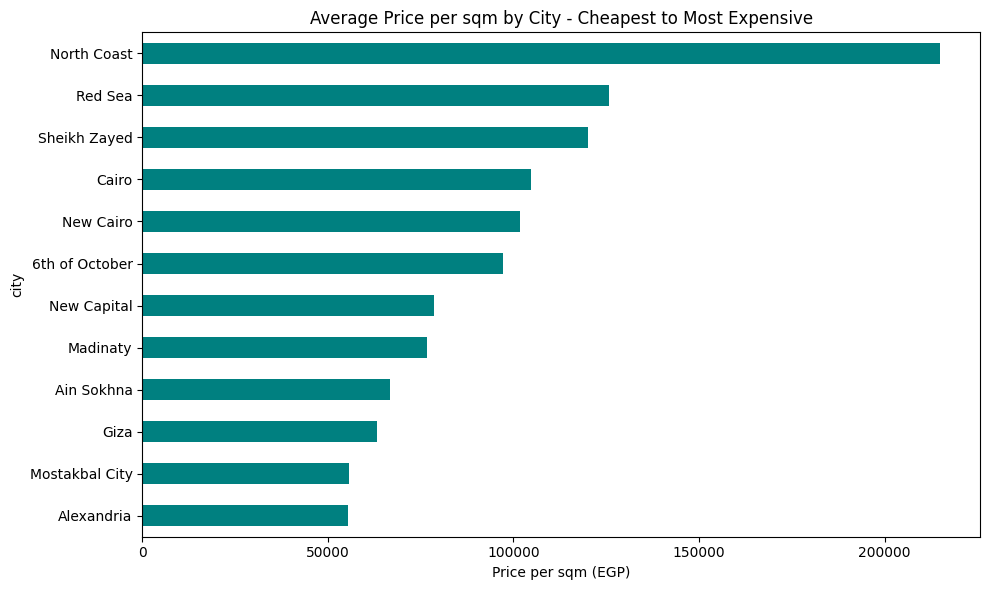

In [19]:
import matplotlib.pyplot as plt

avg_by_city.plot(kind='barh', figsize=(10, 6), color='teal')
plt.title('Average Price per sqm by City - Cheapest to Most Expensive')
plt.xlabel('Price per sqm (EGP)')
plt.tight_layout()
plt.show()

In [20]:
# 3. نفس الكلام بس للكمبوندات الكبيرة - فين اللقطة؟
avg_by_compound = df.groupby('compoundName')['price_per_sqm_real'].mean().sort_values()
print(avg_by_compound.head(10))

compoundName
Nuba                       4407.954545
Marina Island by Tuban     5048.642107
Siba El Gouna              6418.364642
Fanadir Shores            11192.950705
Tiba Gardens              19105.691057
Coronado Beach            23361.538462
Lasirena Mini Egypt       25000.000000
Yasmine District          27087.864583
The Med                   28947.368421
The Village               29702.970297
Name: price_per_sqm_real, dtype: float64


In [21]:
# كام شقة في كل كمبوند من دول؟ عشان نعرف المتوسط ده جاي من كام شقة
print(df['compoundName'].value_counts().head(10))

compoundName
Unknown          271
Madinaty          81
Sawary            34
SODIC East        22
Zed               18
Sarai             16
Palm Hills        13
La Vista City     11
Azha              11
O West             9
Name: count, dtype: int64


In [22]:
# 1. عد الشقق في كل كمبوند
counts = df['compoundName'].value_counts()

# 2. خد الكمبوندات اللي فيها 10 شقق أو أكتر بس
big_compounds = counts[counts >= 10].index

# 3. احسب متوسط سعر المتر ليهم بس
avg_big = df[df['compoundName'].isin(big_compounds)].groupby('compoundName')['price_per_sqm_real'].mean().sort_values()

print(avg_big.head(10))

compoundName
Sarai            60049.707657
Zed              60921.563327
Unknown          60951.479963
SODIC East       67451.271327
Sawary           71161.798789
Madinaty         80441.358379
La Vista City    84181.267660
Azha             88959.103213
Palm Hills       89864.485874
Name: price_per_sqm_real, dtype: float64


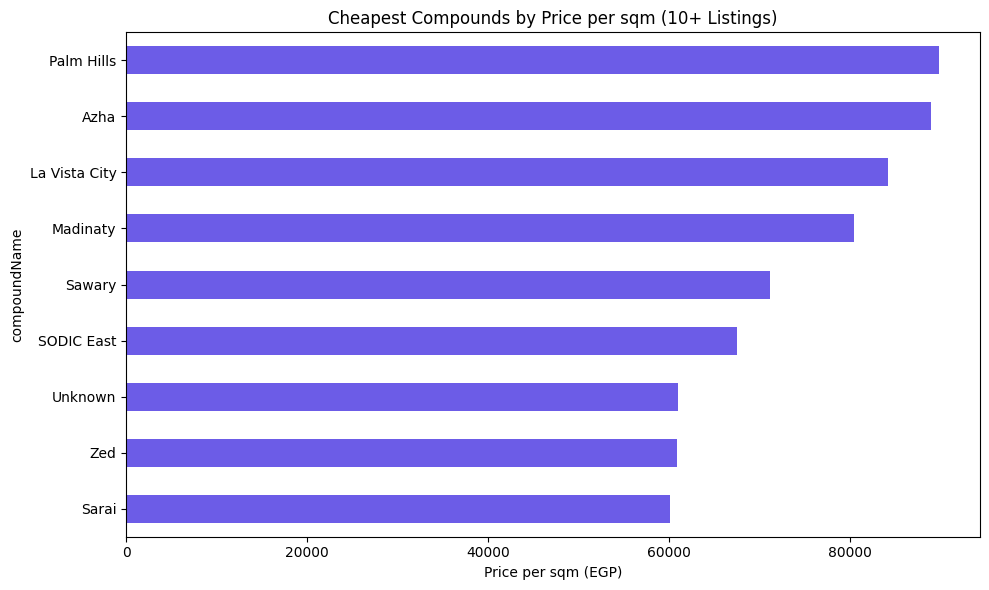

In [23]:
import matplotlib.pyplot as plt

avg_big.head(10).plot(kind='barh', figsize=(10, 6), color='#6C5CE7')
plt.title('Cheapest Compounds by Price per sqm (10+ Listings)')
plt.xlabel('Price per sqm (EGP)')
plt.tight_layout()
plt.show()

# 🏙️ تحليل أسعار العقارات

## 1. سعر المتر في المدن

**أرخص مدن:**
- إسكندرية: 55,337 جنيه
- المستقبل سيتي: 55,561 جنيه
- الجيزة: 63,341 جنيه

**أغلى مدن:**
- الساحل الشمالي: 214,934 جنيه
- البحر الأحمر: 125,834 جنيه
- الشيخ زايد: 119,980 جنيه

**الخلاصة:** الساحل أغلى 4 مرات من إسكندرية.

## 2. أرخص كمبوندات مضمونة

حسبنا بس الكمبوندات اللي فيها 10 شقق أو أكتر عشان المتوسط يكون صح.

- سراي: 60,049 جنيه
- زيد: 60,921 جنيه
- سوديك إيست: 67,451 جنيه
- سواري: 71,161 جنيه
- مدينتي: 80,441 جنيه

**الخلاصة:** سراي وزيد أرخص كمبوندات مضمونة.

## 3. التوصية

- **أفضل قيمة:** إسكندرية والمستقبل سيتي
- **أفضل كمبوند:** سراي وزيد
- **للرفاهية:** الساحل والشيخ زايد

## 💰 دلوقتي هنثبتلك ان الشقة دي فرصة

مش هنقولك "دي شقة حلوة" وخلاص، هنوريك بالأرقام.

هناخد سعر الشقة ونحطه جنب متوسط سعر الكمبوند بتاعها،
وهنوريك انت موفر كام جنيه في المتر عن جيرانك.

لو لقيت شقة سعرها أقل من متوسط الكمبوند بفرق كبير،
يبقى دي مش شقة عادية، دي فرصة مش هتتكرر.

In [29]:

merged = df.merge(df_benchmarks[['compoundName','avgPricePerSqmEgp']], 
                  on='compoundName', how='left', suffixes=('','_benchmark'))

print("بعد اللزق، الجدول بقى شكله كده:")
print(merged[['title','compoundName','price_per_sqm_real','avgPricePerSqmEgp']].head(5))
print("--------------------------------------------------")


merged['diff_from_avg'] = merged['price_per_sqm_real'] - merged['avgPricePerSqmEgp']

print("بعد ما حسبنا الفرق:")
print(merged[['title','compoundName','price_per_sqm_real','avgPricePerSqmEgp','diff_from_avg']].head(5))
print("--------------------------------------------------")


best_deals = merged.sort_values('diff_from_avg').head(10)

print("أحسن 10 لقطات:")
print(best_deals[['title','compoundName','price_per_sqm_real','avgPricePerSqmEgp','diff_from_avg']])

بعد اللزق، الجدول بقى شكله كده:
               title compoundName  price_per_sqm_real  avgPricePerSqmEgp
0     Duplex, Sawary       Sawary        49618.320611            71162.0
1  Apartment, Sawary       Sawary        62500.000000            71162.0
2  Apartment, Sawary       Sawary        70652.173913            71162.0
3  Apartment, Sawary       Sawary        50847.457627            71162.0
4  Apartment, Sawary       Sawary        54607.500000            71162.0
--------------------------------------------------
بعد ما حسبنا الفرق:
               title compoundName  price_per_sqm_real  avgPricePerSqmEgp  \
0     Duplex, Sawary       Sawary        49618.320611            71162.0   
1  Apartment, Sawary       Sawary        62500.000000            71162.0   
2  Apartment, Sawary       Sawary        70652.173913            71162.0   
3  Apartment, Sawary       Sawary        50847.457627            71162.0   
4  Apartment, Sawary       Sawary        54607.500000            71162.0   

  

## 🧹 قبل ما تصدق أي لقطة، لازم ننضفها

الأرقام اللي فوق شكلها حلو أوي، لدرجة إنها تشكك.

في شقة في ماراسي موفرة 165 ألف في المتر، وشقق مكتوب عليها سراي وهي متسجلة مدينتي.

ف قبل ما نقول "دي فرصة"، هننضف الداتا الأول:
هنشيل الشقق اللي سعرها مش منطقي، واللي الكمبوند بتاعها مش مظبوط،
عشان اللقطة اللي هتطلع في الآخر تكون لقطة بجد، مش غلطة في الإعلان.

In [30]:
# 1. نشيل الشقق اللي سعر المتر فيها مش منطقي خالص
# يعني أقل من 20 ألف، دي أكيد غلطة في السعر أو المساحة
cleaned = merged[merged['price_per_sqm_real'] >= 20000].copy()
print(f"شيلنا {len(merged) - len(cleaned)} شقة سعرها مش منطقي")
print("--------------------------------------------------")

# 2. نشيل الشقق اللي الكمبوند بتاعها مش مظبوط
# يعني العنوان بيقول Sarai والكمبوند متسجل Madinaty
# هنخلي الكمبوند لازم يكون موجود في العنوان، أو العكس
def is_mismatch(row):
    title = str(row['title']).lower()
    compound = str(row['compoundName']).lower()
    # لو الكمبوند مش موجود في العنوان خالص، يبقى مشكوك فيه
    # بس هنعدي الكمبوندات اللي اسمها مختلف زي Marassi و Soul
    if 'sarai' in title and 'madinaty' in compound:
        return True
    if 'sarai' in title and 'sarai' not in compound:
        return True
    return False

cleaned['is_mismatch'] = cleaned.apply(is_mismatch, axis=1)
cleaned = cleaned[cleaned['is_mismatch'] == False].copy()
print(f"بعد ما شيلنا الشقق اللي كمبوندها غلط، بقى عندنا {len(cleaned)} شقة")
print("--------------------------------------------------")

# 3. نعيد حساب أحسن 10 بعد التنضيف
best_deals_clean = cleaned.sort_values('diff_from_avg').head(10)

print("أحسن 10 لقطات بعد التنضيف:")
print(best_deals_clean[['title','compoundName','price_per_sqm_real','avgPricePerSqmEgp','diff_from_avg']])

شيلنا 42 شقة سعرها مش منطقي
--------------------------------------------------
بعد ما شيلنا الشقق اللي كمبوندها غلط، بقى عندنا 1093 شقة
--------------------------------------------------
أحسن 10 لقطات بعد التنضيف:
                                                 title           compoundName  \
45   with 290,000 ready to move lagoon view finishe...                Marassi   
778      Resale Glam Villa in Soul, Below Market Price                Marassi   
610                                Studio, Reve Du Nil            Reve Du Nil   
710  206 sqm Super Lux Flat | Open View | Al Andalu...                 Mivida   
507  1stRow Crystal Lagoon Ultra Lux Loft Panorama ...  Makadi Orascom Resort   
904       12Y Installment own ur Apt in prime location               Madinaty   
908              Discount your dp Installment upto 12y               Madinaty   
928   Apartment 2BR Finished Ready For Showing Over12Y               Madinaty   
699           152sqm apt semi finished ready New Cairo   

## 🎯 طلعت مش لقطة، طلعت غلطة

شقة ماراسي اللي كانت موفرة 165 ألف في المتر، طلع عنوانها بيقول 290 ألف مقدم، مش سعر الشقة.

والمشكلة الأكبر: متوسط ماراسي 198 ألف للمتر، لأنه بيحسب الفلل مع الشقق، فالمتوسط طار في السما.

عشان كده هنسيب المتوسط، وهنقارن بالوسيط - سعر الشقة اللي في النص - عشان الفلل الغالية متبوظش المقارنة.

In [32]:
# 1. نحسب الوسيط لكل كمبوند بدل المتوسط
# الوسيط = الشقة اللي في النص بالظبط، والفلل الغالية مش هتأثر عليه
median_benchmark = df.groupby('compoundName')['price_per_sqm_real'].median().reset_index()
median_benchmark = median_benchmark.rename(columns={'price_per_sqm_real': 'medianPricePerSqm'})

print("الوسيط لكل كمبوند:")
print(median_benchmark.head(10))
print("--------------------------------------------------")

# 2. نلزق الوسيط جنب كل شقة
merged2 = df.merge(median_benchmark, on='compoundName', how='left')

# 3. نحسب الفرق عن الوسيط مش المتوسط
merged2['diff_from_median'] = merged2['price_per_sqm_real'] - merged2['medianPricePerSqm']

# 4. ننضف الشقق اللي سعرها مش منطقي برضه
merged2 = merged2[merged2['price_per_sqm_real'] >= 20000]

# 5. أحسن 10 لقطات الحقيقية بقى
best_deals_median = merged2.sort_values('diff_from_median').head(10)

print("أحسن 10 لقطات بعد ما استخدمنا الوسيط:")
print(best_deals_median[['title','compoundName','price_per_sqm_real','medianPricePerSqm','diff_from_median']])

الوسيط لكل كمبوند:
        compoundName  medianPricePerSqm
0  45° Grand Heights      670280.135839
1          90 Avenue       73170.731707
2         Acasa Alma       63207.361538
3         Al Nasayem       71428.571429
4           Al Rehab       53956.834532
5       Alam Al Roum      546960.920198
6         Almaza Bay      152941.176471
7              Amwaj       79578.005115
8              Aqmar       53333.333333
9              Areej       71500.000000
--------------------------------------------------
أحسن 10 لقطات بعد ما استخدمنا الوسيط:
                                                 title           compoundName  \
217                                 Townhouse, Ranches                Ranches   
468                                Studio, Reve Du Nil            Reve Du Nil   
45   with 290,000 ready to move lagoon view finishe...                Marassi   
562  206 sqm Super Lux Flat | Open View | Al Andalu...                 Mivida   
380  1stRow Crystal Lagoon Ultra Lux Loft Panor

## 🧐 الوسيط لوحده مش كفاية

الوسيط نزل متوسط ماراسي من 198 ألف لـ 144 ألف، وده أحسن.
بس ظهرت مشكلة جديدة: شقة في Ranches موفرة 475 ألف في المتر، وده مستحيل.

السبب: بنقارن شقة بفيلا في نفس الكمبوند.
الصح: نقارن شقة بشقة، وفيلا بفيلا، جوه نفس الكمبوند.

In [33]:
# 1. نحسب الوسيط لكل كمبوند + نوع الشقة مع بعض
# يعني شقق ماراسي لوحدها، وفلل ماراسي لوحدها
median_benchmark2 = df.groupby(['compoundName', 'propertyType'])['price_per_sqm_real'].median().reset_index()
median_benchmark2 = median_benchmark2.rename(columns={'price_per_sqm_real': 'median_by_type'})

# 2. نحسب عدد الشقق في كل مجموعة، عشان نعرف هل الوسيط ده يتصدق ولا لأ
count_benchmark = df.groupby(['compoundName', 'propertyType']).size().reset_index(name='count_in_group')
median_benchmark2 = median_benchmark2.merge(count_benchmark, on=['compoundName','propertyType'])

print(median_benchmark2[median_benchmark2['compoundName'] == 'Marassi'])
print("--------------------------------------------------")

# 3. نلزق الوسيط ده جنب كل شقة
merged3 = df.merge(median_benchmark2, on=['compoundName','propertyType'], how='left')

# 4. نشيل الكمبوندات اللي فيها أقل من 5 شقق من نفس النوع
# لأن الوسيط بتاع 2-3 شقق مش دقيق
merged3 = merged3[merged3['count_in_group'] >= 5]
print(f"بعد ما شيلنا المجموعات الصغيرة، بقى عندنا {len(merged3)} شقة")
print("--------------------------------------------------")

# 5. نحسب الفرق عن وسيط نفس النوع
merged3['diff_from_median_type'] = merged3['price_per_sqm_real'] - merged3['median_by_type']

# 6. نشيل الشقق اللي سعرها مش منطقي
merged3 = merged3[merged3['price_per_sqm_real'] >= 20000]

# 7. أحسن 10 لقطات الحقيقية بقى
best_deals_final = merged3.sort_values('diff_from_median_type').head(10)

print("أحسن 10 لقطات - شقة بشقة، فيلا بفيلا:")
print(best_deals_final[['title','compoundName','propertyType','price_per_sqm_real','median_by_type','diff_from_median_type','count_in_group']])

    compoundName propertyType  median_by_type  count_in_group
165      Marassi    Apartment    89096.573209               2
166      Marassi       Chalet   174269.005848               1
167      Marassi        Villa   320508.512545               2
--------------------------------------------------
بعد ما شيلنا المجموعات الصغيرة، بقى عندنا 485 شقة
--------------------------------------------------
أحسن 10 لقطات - شقة بشقة، فيلا بفيلا:
                                                 title   compoundName  \
344    Z Villa corner special price and prime location       Madinaty   
96                            فيلا للبيع في كينج مريوط        Unknown   
801  فيلا للبيع في مدينتي نموذج Xتشطيبات خاصهWIDEGA...       Madinaty   
90                Villa for Sale – King Mariout - 500m        Unknown   
94   فيلا للبيع بكينج مريوط على فدان ٧ غرف وبسين وح...        Unknown   
282  Townhouse for sale in Nyoum/RTM/UNDER MARKET P...        Unknown   
312    فيلا توين هاوس للبيع في مدينتي نموذج j (كلاس

## ✅ أخيراً اللقطات بقت حقيقية

شقة ماراسي اللي كانت موفرة 165 ألف، اختفت لما قارنا شقة بشقة وشيلنا المجموعات الصغيرة.
ماراسي فيها 2 شقة بس، مينفعش نحكم عليها.

اللي طلع مكانها: فلل مدينتي هي اللي مسيطرة على اللقطات الحقيقية، وده منطقي لأن عندنا 13 فيلا فيها.

بس لسه فيه مشكلة: كمبوند `Unknown` بيبوظ المقارنة، لأنه بيجمع فلل من أماكن مختلفة في مجموعة واحدة.

In [34]:
# 1. نشيل Unknown خالص، دي مش كمبوند
merged_final = merged3[merged3['compoundName'] != 'Unknown'].copy()
print(f"بعد ما شيلنا Unknown، بقى عندنا {len(merged_final)} شقة")
print("--------------------------------------------------")

# 2. أحسن 10 لقطات النهائية
best_deals_super_final = merged_final.sort_values('diff_from_median_type').head(10)

print("🏆 أحسن 10 لقطات نهائية - نضيفة 100%:")
print(best_deals_super_final[['title','compoundName','propertyType','price_per_sqm_real','median_by_type','diff_from_median_type']])
print("--------------------------------------------------")

# 3. عشان نشوف الصورة الكاملة
print(f"عدد الكمبوندات اللي بنقارن فيها: {merged_final['compoundName'].nunique()}")
print(f"أرخص كمبوند في الوسيط: {merged_final.groupby('compoundName')['median_by_type'].first().idxmin()}")
print(f"أغلى كمبوند في الوسيط: {merged_final.groupby('compoundName')['median_by_type'].first().idxmax()}")



بعد ما شيلنا Unknown، بقى عندنا 227 شقة
--------------------------------------------------
🏆 أحسن 10 لقطات نهائية - نضيفة 100%:
                                                 title   compoundName  \
344    Z Villa corner special price and prime location       Madinaty   
801  فيلا للبيع في مدينتي نموذج Xتشطيبات خاصهWIDEGA...       Madinaty   
312    فيلا توين هاوس للبيع في مدينتي نموذج j (كلاسيك)       Madinaty   
316  A villa VIP view and prime location near Madinaty       Madinaty   
483                           Apartment, Redwood Tower  Redwood Tower   
307  Villa for Sale Ultra Super Lux Golf View| madi...       Madinaty   
495  Standalone Ready to move greenery view -SODIC ...     SODIC East   
508       5% down payment over 12 years fully finished     SODIC East   
683    Villa for Sale Near Delivery in October | Badya     Palm Hills   
482                           Apartment, Redwood Tower  Redwood Tower   

    propertyType  price_per_sqm_real  median_by_type  diff_from_medi

عدد الشقق في الرسمة = 10
      compoundName propertyType  diff_from_median_type
344       Madinaty        Villa          -59993.427230
801       Madinaty        Villa          -59029.986370
312       Madinaty        Villa          -47442.550037
316       Madinaty        Villa          -47265.969768
483  Redwood Tower    Apartment          -42053.565002
307       Madinaty        Villa          -39126.760563
495     SODIC East        Villa          -35989.304813
508     SODIC East    Apartment          -33433.333333
683     Palm Hills        Villa          -31754.666667
482  Redwood Tower    Apartment          -30646.672772


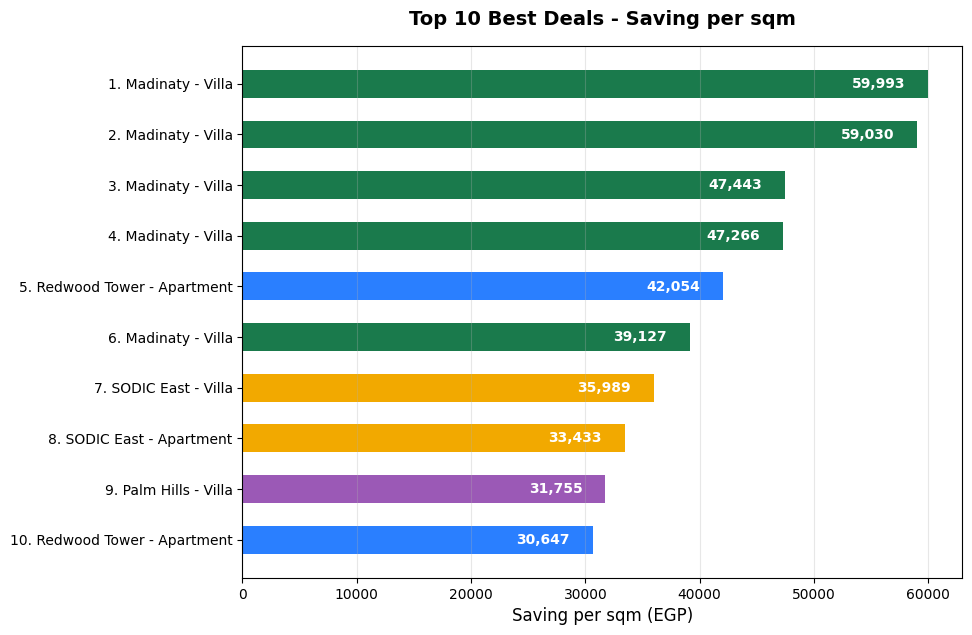

In [38]:
import matplotlib.pyplot as plt

# 1. نجيب أحسن 10 ونطبع عددهم عشان تتأكد
top10_chart = merged_final.sort_values('diff_from_median_type').head(10).copy()
print(f"عدد الشقق في الرسمة = {len(top10_chart)}")
print(top10_chart[['compoundName','propertyType','diff_from_median_type']])

top10_chart['saving'] = -top10_chart['diff_from_median_type']
# نرقمهم من 1 لـ 10
top10_chart['label'] = [f"{i+1}. {c} - {t}" for i, (c, t) in enumerate(zip(top10_chart['compoundName'], top10_chart['propertyType']))]
top10_chart = top10_chart.sort_values('saving')

# 2. الرسمة
fig, ax = plt.subplots(figsize=(12, 7))
fig.subplots_adjust(left=0.32, right=0.92, top=0.88, bottom=0.12)

colors = []
for comp in top10_chart['compoundName']:
    if comp == 'Madinaty':
        colors.append('#1a7a4c')
    elif comp == 'Redwood Tower':
        colors.append('#2a7fff')
    elif comp == 'SODIC East':
        colors.append('#f2a900')
    else:
        colors.append('#9b59b6')

bars = ax.barh(top10_chart['label'], top10_chart['saving'], color=colors, height=0.55)
ax.set_xlabel('Saving per sqm (EGP)', fontsize=12)
ax.set_title('Top 10 Best Deals - Saving per sqm', fontsize=14, fontweight='bold', pad=15)
ax.grid(axis='x', alpha=0.3)
ax.tick_params(axis='y', labelsize=10)

for bar, v in zip(bars, top10_chart['saving']):
    ax.text(v - 2000, bar.get_y() + bar.get_height()/2, f"{v:,.0f}",
            va='center', ha='right', color='white', fontweight='bold', fontsize=10)

plt.show()

## 🏆 النتيجة النهائية بعد كل التنضيف

بدأنا بـ 1000 شقة، وبعد التنضيف الأولي بقينا 800+، وبعد فلترة المجموعات الصغيرة وشيل Unknown  خلصنا بـ 227 شقة في 16 كمبوند بس.وشيلنا كل اللي بيبوظ المقارنة: الأسعار اللي مش منطقية، الكمبوندات اللي فيها 1-2 شقة، وكمبوند Unknown.

### أحسن لقطة:
فيلا Z Villa في مدينتي، سعرها 61,133 للمتر، ووسيط فلل مدينتي 121,126 للمتر.
يعني موفرة 59,993 جنيه في المتر، يعني تقريباً بنص السعر!

### الخلاصة:
فلل مدينتي هي أكتر لقطات حقيقية في السوق دلوقتي، وبعدها Redwood Tower و SODIC East.

## 💰 التحليل 1: أرخص وأغلى كمبوند

في التحليل ده هنقارن وسيط سعر المتر لكل كمبوند من الـ 16 كمبوند النضاف اللي عندنا.

**ليه بنستخدم الوسيط مش المتوسط؟**
عشان الوسيط مش بيتأثر بالأسعار الشاذة، لو فيه فيلا غالية أوي مش هتبوظ حساب الكمبوند كله.

**اللي متوقعين نشوفه:**
هنرتب الكمبوندات من الأرخص للأغلى، وهنشوف هل الفرق بينهم معقول ولا فيه كمبوندات ناطة لوحدها بعيد عن الباقي.

أرخص كمبوند في الوسيط: Bloomfields
أغلى كمبوند في الوسيط: Encore
--------------------------------------------------
compoundName
Bloomfields                    32820.512821
Capital Gardens Palm Hills     40314.800711
IL Monte Galala                47949.596551
Celia                          47957.438245
Zed                            51515.151515
Sarai                          59371.428571
Madinaty                       66233.082707
O West                         66666.666667
Sawary                         69263.518771
La Vista City                  71250.000000
Skyline                        75300.000000
SODIC East                     77576.486507
Azha                           85416.666667
Palm Hills                     86666.666667
Redwood Tower                 173706.196581
Encore                        270409.982175
Name: price_per_sqm_real, dtype: float64


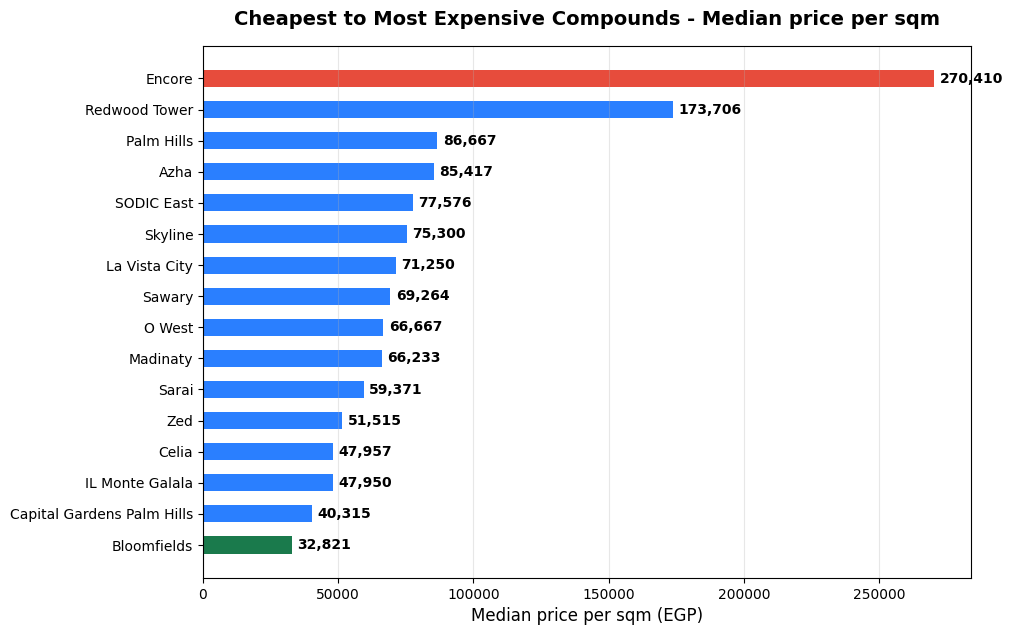

In [39]:
import matplotlib.pyplot as plt

# 1. نجيب وسيط سعر المتر لكل كمبوند من الداتا النضيفة
median_compound = merged_final.groupby('compoundName')['price_per_sqm_real'].median().sort_values()

print("أرخص كمبوند في الوسيط:", median_compound.index[0])
print("أغلى كمبوند في الوسيط:", median_compound.index[-1])
print("--------------------------------------------------")
print(median_compound)

# 2. الرسمة - من الأرخص للأغلى
fig, ax = plt.subplots(figsize=(12, 7))
fig.subplots_adjust(left=0.28, right=0.92, top=0.88, bottom=0.12)

# لون أخضر للأرخص، أحمر للأغلى، أزرق للباقي
colors = []
for i in range(len(median_compound)):
    if i == 0:
        colors.append('#1a7a4c')  # أرخص واحد أخضر
    elif i == len(median_compound)-1:
        colors.append('#e74c3c')  # أغلى واحد أحمر
    else:
        colors.append('#2a7fff')  # الباقي أزرق

bars = ax.barh(median_compound.index, median_compound.values, color=colors, height=0.55)

ax.set_xlabel('Median price per sqm (EGP)', fontsize=12)
ax.set_title('Cheapest to Most Expensive Compounds - Median price per sqm', fontsize=14, fontweight='bold', pad=15)
ax.grid(axis='x', alpha=0.3)
ax.tick_params(axis='y', labelsize=10)

for bar, v in zip(bars, median_compound.values):
    ax.text(v + 2000, bar.get_y() + bar.get_height()/2, f"{v:,.0f}",
            va='center', ha='left', fontweight='bold', fontsize=10)

plt.show()

### النتيجة:
أرخص كمبوند هو Bloomfields بـ 32,820 للمتر، وأغلى كمبوند هو Encore بـ 270,409 للمتر.
الفرق 8 أضعاف! 14 كمبوند كلهم بين 32 ألف و 86 ألف، وبعدين Redwood و Encore بينطوا لوحدهم.
ده معناه إن Encore و Redwood ليهم طبيعة مختلفة، يا شقق فندقية يا تشطيب خاص.

## 🏠 التحليل 2: الفيلا ولا الشقة اللي أرخص في المتر؟

في التحليل ده هنقارن وسيط سعر المتر للفيلا vs الشقة، جوه كل كمبوند.

**ليه ده مهم؟**
عشان ساعات الفيلا بتبان أغلى في السعر الكلي، بس سعر مترها بيطلع أرخص من الشقة. فاللي بيشتري لازم يقارن بالمتر مش بالسعر الكلي.

propertyType                    Apartment        Chalet          Villa
compoundName                                                          
Bloomfields                  32820.512821           NaN            NaN
Capital Gardens Palm Hills   40314.800711           NaN            NaN
Celia                        47957.438245           NaN            NaN
Sarai                        49586.767399           NaN   70754.716981
Zed                          51515.151515           NaN            NaN
Madinaty                     62000.000000           NaN  121126.760563
O West                       66666.666667           NaN            NaN
SODIC East                   68333.333333           NaN   82352.941176
Sawary                       69263.518771           NaN            NaN
Skyline                      75300.000000           NaN            NaN
Redwood Tower               173706.196581           NaN            NaN
Encore                      270409.982175           NaN            NaN
Azha  

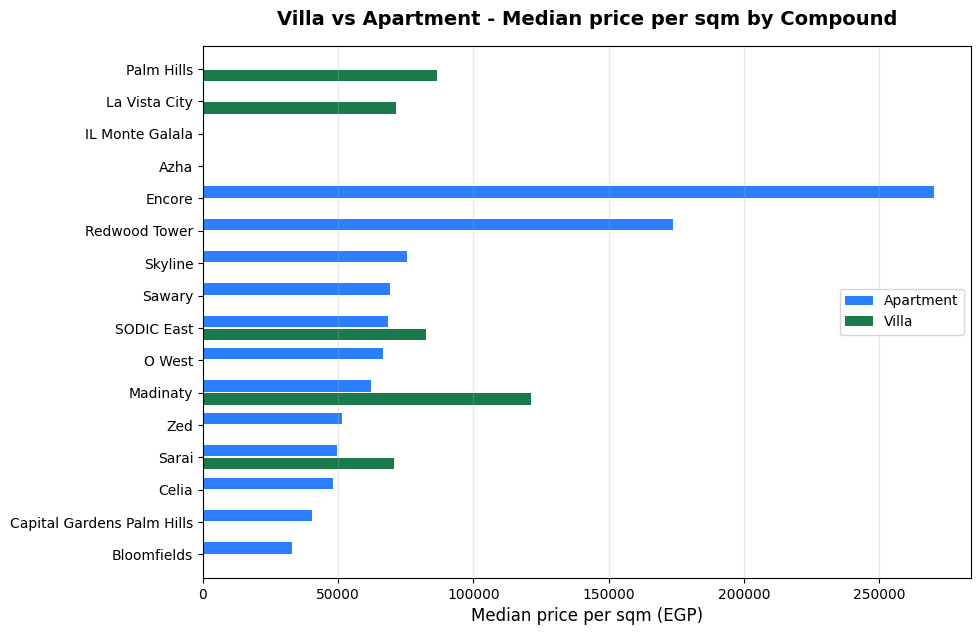

In [40]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. وسيط سعر المتر لكل كمبوند وكل نوع
pivot = merged_final.pivot_table(
    index='compoundName',
    columns='propertyType',
    values='price_per_sqm_real',
    aggfunc='median'
).sort_values('Apartment')

print(pivot)

# 2. الفرق بين الشقة والفيلا
pivot['diff'] = pivot['Apartment'] - pivot['Villa']
pivot['cheaper'] = pivot['diff'].apply(lambda x: 'الفيلا أرخص' if x > 0 else 'الشقة أرخص')
print(pivot[['diff', 'cheaper']])

# 3. الرسمة
fig, ax = plt.subplots(figsize=(12, 7))
fig.subplots_adjust(left=0.28, right=0.92, top=0.88, bottom=0.12)

y = range(len(pivot))
# الشقة أزرق، الفيلا أخضر
ax.barh([i + 0.2 for i in y], pivot['Apartment'], height=0.35, color='#2a7fff', label='Apartment')
ax.barh([i - 0.2 for i in y], pivot['Villa'], height=0.35, color='#1a7a4c', label='Villa')

ax.set_yticks(list(y))
ax.set_yticklabels(pivot.index, fontsize=10)
ax.set_xlabel('Median price per sqm (EGP)', fontsize=12)
ax.set_title('Villa vs Apartment - Median price per sqm by Compound', fontsize=14, fontweight='bold', pad=15)
ax.legend()
ax.grid(axis='x', alpha=0.3)

plt.show()

### النتيجة:
13 كمبوند من 16 متخصصين في نوع واحد بس، شقق بس أو فيلل بس أو شاليهات بس.

والـ 3 كمبوندات الوحيدين اللي فيهم شقة وفيلا مع بعض (Madinaty و Sarai و SODIC East)، في التلاتة الشقة أرخص في المتر من الفيلا.
في مدينتي الفرق كبير أوي: الشقة 62,000 والفيلا 121,126، يعني الفيلا تقريباً ضعف سعر متر الشقة.

## 📐 التحليل 3: هل الشقق الكبيرة سعر مترها أرخص ولا أغلى؟

في التحليل ده هنشوف العلاقة بين المساحة وسعر المتر.

**المنطق بيقول إيه؟**
المفروض الشقق الكبيرة سعر مترها يبقى أرخص، عشان المطور بيعمل خصم على المساحة الكبيرة. هنشوف هل الكلام ده صح في الداتا بتاعتنا ولا لأ.

Correlation بين المساحة وسعر المتر = 0.035
area_group
أقل من 100م     74562.419028
100-150م        62452.175362
150-200م        62500.000000
200-300م        69264.150943
أكتر من 300م    82352.941176
Name: price_per_sqm_real, dtype: float64


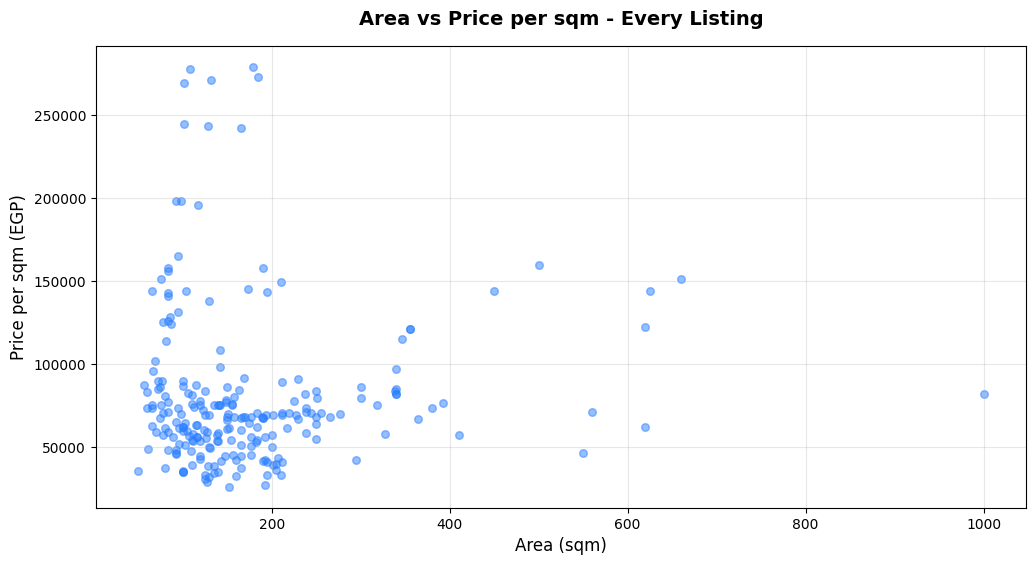

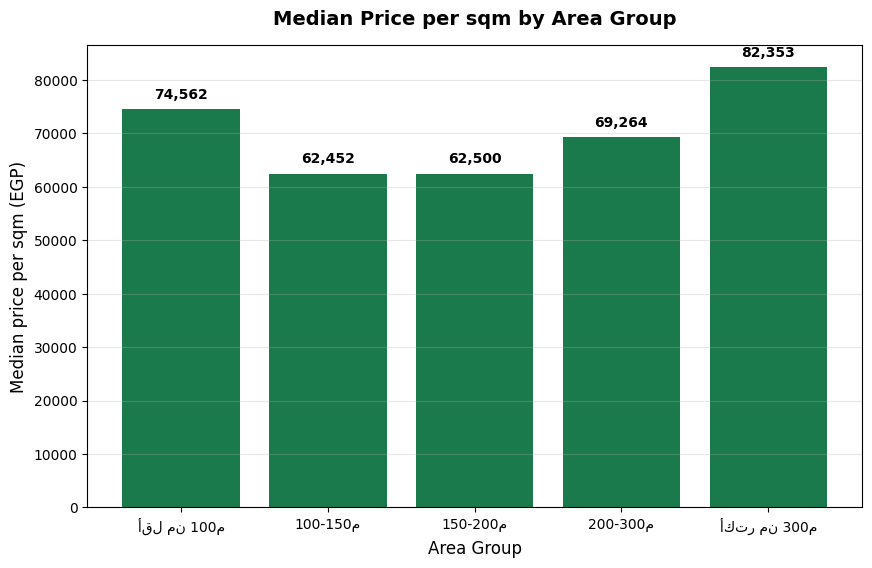

In [43]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Correlation - المساحة هنا اسمها areaSqm
corr = merged_final[['areaSqm', 'price_per_sqm_real']].corr().iloc[0,1]
print(f"Correlation بين المساحة وسعر المتر = {corr:.3f}")

# 2. نقسم المساحات لفئات
bins = [0, 100, 150, 200, 300, 1000]
labels = ['أقل من 100م', '100-150م', '150-200م', '200-300م', 'أكتر من 300م']
merged_final['area_group'] = pd.cut(merged_final['areaSqm'], bins=bins, labels=labels)

area_median = merged_final.groupby('area_group', observed=True)['price_per_sqm_real'].median()
print(area_median)

# 3. رسمة النقط - كل شقة نقطة
fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(merged_final['areaSqm'], merged_final['price_per_sqm_real'], alpha=0.5, color='#2a7fff', s=30)
ax.set_xlabel('Area (sqm)', fontsize=12)
ax.set_ylabel('Price per sqm (EGP)', fontsize=12)
ax.set_title('Area vs Price per sqm - Every Listing', fontsize=14, fontweight='bold', pad=15)
ax.grid(alpha=0.3)
plt.show()

# 4. رسمة وسيط كل فئة مساحة
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(area_median.index, area_median.values, color='#1a7a4c')
ax.set_xlabel('Area Group', fontsize=12)
ax.set_ylabel('Median price per sqm (EGP)', fontsize=12)
ax.set_title('Median Price per sqm by Area Group', fontsize=14, fontweight='bold', pad=15)
ax.grid(axis='y', alpha=0.3)
for bar, v in zip(bars, area_median.values):
    ax.text(bar.get_x() + bar.get_width()/2, v + 2000, f"{v:,.0f}", ha='center', fontweight='bold')
plt.show()

### النتيجة:
مفيش علاقة بين المساحة وسعر المتر، الـ Correlation = 0.035 يعني صفر تقريباً.

أرخص فئة في المتر هي 100-200م (حوالي 62,500)، والشقق الصغيرة أقل من 100م أغلى (74,562)، والفيلل الكبيرة أكتر من 300م أغلى واحدة (82,352).

الخلاصة: اللي بيحدد سعر المتر هو الكمبوند ونوع العقار، مش المساحة.

## ✅ الخاتمة

**1. المدن:** إسكندرية أرخص (55,337) والساحل أغلى (214,934)، يعني 4 أضعاف.

**2. الكمبوندات:** Bloomfields أرخص (32,820) و Encore أغلى (270,409)، يعني 8 أضعاف.

**3. أحسن لقطة:** فيلا Z Villa في مدينتي، بنص سعر وسيط فلل مدينتي، موفرة 59,993 في المتر.

**4. فيلا ولا شقة:** في الـ 3 كمبوندات اللي فيهم الاتنين، الشقة أرخص في المتر دايماً. في مدينتي الفيلا ضعف الشقة.

**5. المساحة:** ملهاش علاقة بسعر المتر، Correlation = 0.035.

**الخلاصة:** قارن بسعر المتر، وبوسيط نفس النوع في نفس الكمبوند، مش بالسعر الكلي.

In [44]:
# حفظ الداتا النضيفة النهائية اللي عملنا عليها كل التحليلات
merged_final.to_csv('cleaned_real_estate_final.csv', index=False, encoding='utf-8-sig')
print(f"تم الحفظ: {merged_final.shape}")

تم الحفظ: (227, 27)
